# Week 4 on Kaggle: does the mechanism predict damage, across stages and models?

Three new experiments, all forward passes through frozen models (nothing is trained):

1. **W4-2 Geometry for every call stage and three detectors.** For all 22 call stages, and for checkpoint A, checkpoint B and XLSR-SLS (same XLS-R front end, but a back end that reads all 24 layers), measure how far each stage moves genuine and spoofed speech along the clean real-to-fake axis at every layer, and how much each stage hurts the detector.
2. **W4-3 The predictor.** Does the genuine drift at the layer(s) the back end reads predict which stages break each detector? Compared against an unprojected drift size (control).
3. **W4-4 Axis split.** Split the layer-17 drift of checkpoint A into the part along the real-to-fake axis and the part orthogonal to it, add or remove each part separately, and compare with a norm-matched drift from a harmless stage and random directions.

**Before you run:** Settings: **GPU T4 x2**, **Internet On**. Your Kaggle input dataset is the same as week 3. It must also contain **`LA_model.pth`** (checkpoint B); step 0 finds it anywhere in the dataset. If it is missing, add it to the dataset first (it is in your Drive from week 1).

Then **Save Version → Save & Run All (Commit)**. About 3–4 hours. At the end, download `week4_for_github.zip` and `week4_summary.txt` from the version's Output tab and send the summary to Claude.

In [1]:
#@title 0 · Kaggle: fetch your data and lay it out like the Drive folder
DRIVE_ZIP_LINK = 'https://drive.google.com/file/d/1pzQ1AoDFrY682zaKn8lEorvy7sv8vE7Z/view?usp=sharing'  

import os, glob, shutil, subprocess
OUTP = '/kaggle/working/fyp_pilot'
SEARCH = ['/kaggle/input']
if DRIVE_ZIP_LINK:
    subprocess.run(['pip', '-q', 'install', 'gdown'], check=True)
    import gdown
    os.makedirs('/tmp/_in', exist_ok=True)
    if not os.path.exists('/tmp/fyp_kaggle.zip'):
        gdown.download(url=DRIVE_ZIP_LINK, output='/tmp/fyp_kaggle.zip', fuzzy=True, quiet=False)
    if not glob.glob('/tmp/_in/**/subset.csv', recursive=True):
        subprocess.run(['unzip', '-q', '-o', '/tmp/fyp_kaggle.zip', '-d', '/tmp/_in'], check=True)
    SEARCH.insert(0, '/tmp/_in')

def find(pattern, dirs=False):
    hits = []
    for root in SEARCH:
        hits += [h for h in glob.glob(f'{root}/**/{pattern}', recursive=True) if os.path.isdir(h) == dirs]
    return sorted(hits)

os.makedirs(OUTP, exist_ok=True)
sub = find('subset.csv'); assert sub, 'subset.csv not found: check the zip link (option A) or Add Input (option B).'
shutil.copy(sub[0], f'{OUTP}/subset.csv')
import pandas as _pd
first = _pd.read_csv(sub[0]).utt.iloc[0]
flac = find(f'{first}.flac'); assert flac, f'audio subset not found (looked for {first}.flac)'
if not os.path.exists(f'{OUTP}/subset'):
    os.symlink(os.path.dirname(flac[0]), f'{OUTP}/subset')
ck = find('Best_LA_model_for_DF.pth'); assert ck, 'Best_LA_model_for_DF.pth not found'
os.makedirs(f'{OUTP}/checkpoints', exist_ok=True)
if not os.path.exists(f'{OUTP}/checkpoints/Best_LA_model_for_DF.pth'):
    os.symlink(ck[0], f'{OUTP}/checkpoints/Best_LA_model_for_DF.pth')
ckb = find('LA_model.pth')
if ckb and not os.path.exists(f'{OUTP}/checkpoints/LA_model.pth'):
    os.symlink(ckb[0], f'{OUTP}/checkpoints/LA_model.pth')
print('checkpoint B:', ckb[0] if ckb else 'NOT FOUND: add LA_model.pth to your Kaggle dataset, or B is skipped')
sc = [h for h in find('dev__clean.csv') if os.path.basename(os.path.dirname(h)) == 'scores' and '/run_' not in h]
assert sc, 'scores/dev__clean.csv not found (checkpoint A scores from weeks 1-2)'
shutil.copytree(os.path.dirname(sc[0]), f'{OUTP}/scores', dirs_exist_ok=True)
lay = find('layers_clean.npz'); assert lay, 'week2/inside_A/layers_clean.npz not found'
os.makedirs(f'{OUTP}/week2', exist_ok=True)
if not os.path.exists(f'{OUTP}/week2/inside_A'):
    os.symlink(os.path.dirname(lay[0]), f'{OUTP}/week2/inside_A')
w3 = [d for d in find('week3', dirs=True) if not d.startswith(OUTP)]
if w3:
    shutil.copytree(w3[0], f'{OUTP}/week3', dirs_exist_ok=True)
print('subset:', os.path.dirname(flac[0])); print('checkpoint:', ck[0]); print('scores:', os.path.dirname(sc[0]))
print('layers:', os.path.dirname(lay[0])); print('earlier week-3 results:', w3[0] if w3 else 'none (starting fresh)')

Downloading...
From (original): https://drive.google.com/uc?id=1pzQ1AoDFrY682zaKn8lEorvy7sv8vE7Z
From (redirected): https://drive.google.com/uc?id=1pzQ1AoDFrY682zaKn8lEorvy7sv8vE7Z&confirm=t&uuid=ce2b92fc-dc72-4091-8a6e-be88150a1ece
To: /tmp/fyp_kaggle.zip
100%|██████████| 1.72G/1.72G [00:15<00:00, 110MB/s] 


checkpoint B: /kaggle/input/datasets/kithminadev/ssl-aasist-checkpoint-b/LA_model.pth
subset: /tmp/_in/fyp_pilot/subset
checkpoint: /tmp/_in/fyp_pilot/checkpoints/Best_LA_model_for_DF.pth
scores: /tmp/_in/fyp_pilot/scores
layers: /tmp/_in/fyp_pilot/week2/inside_A
earlier week-3 results: none (starting fresh)


In [2]:
#@title 1 · Settings (week 4)
import os, json, time, glob
CFG = dict(
    SEED=1234, BATCH=16,
    OUT='/kaggle/working/fyp_pilot',      # the week-1 folder
    WORK='/kaggle/working/work',
    RUN_DETECTORS=['A', 'B', 'AASIST'],          # A = Best_LA_model_for_DF.pth, B = LA_model.pth, AASIST = Jung et al.
    INSIDE_CKPTS=['A'],                          # steps 7-9; add 'B' only if you have spare time
    INSIDE_LAYERS=[5, 11, 17, 23],               # layers (0-23) used for the test-time fix in step 9
    RESCORE_FOR_LLR=True,                        # re-score week-1 stages once to also save the 'fake' logit
    # Optional: folder in your Drive with the Mendeley ElevenLabs/Respeecher clips (unzipped). '' = skip.
    ELEVEN_DIR='https://drive.google.com/drive/folders/1OzhGZXrlxjbBYN1oNh0f_5cmPl1SefCv?usp=sharing',
    # ---- week 3 ----
    CAND_LAYERS=[3, 5, 7, 9, 11, 13, 15, 17, 19, 21, 23],   # candidate layers for the fit-half choice
    GATE_LAYER=3,                                             # early layer used by the phone-call gate
    N_BOOT=1000,                                              # bootstrap resamples for 95% intervals
    DO_2021=True,                                             # step 13: ASVspoof 2021 LA (about 7.6 GB download)
    N21=120,
    # ---- week 4 ----
    W4_MODELS=['A', 'B', 'SLS'],          # SSL-AASIST checkpoints A and B, and XLSR-SLS (Zhang et al., ACM MM 2024)
    SPLIT_LAYERS=[11, 17],                # layers for the axis-split test (W4-4)
    N_RAND=5,                             # random directions per stage and layer in W4-4
)
for d in (CFG['WORK'], f"{CFG['OUT']}/figures", f"{CFG['OUT']}/week2"):
    os.makedirs(d, exist_ok=True)
assert os.path.exists(f"{CFG['OUT']}/subset.csv"), 'Week-1 folder not found: run the week-1 notebook first, or fix CFG["OUT"].'
print(json.dumps(CFG, indent=1))

{
 "SEED": 1234,
 "BATCH": 16,
 "OUT": "/kaggle/working/fyp_pilot",
 "WORK": "/kaggle/working/work",
 "RUN_DETECTORS": [
  "A",
  "B",
  "AASIST"
 ],
 "INSIDE_CKPTS": [
  "A"
 ],
 "INSIDE_LAYERS": [
  5,
  11,
  17,
  23
 ],
 "RESCORE_FOR_LLR": true,
 "ELEVEN_DIR": "https://drive.google.com/drive/folders/1OzhGZXrlxjbBYN1oNh0f_5cmPl1SefCv?usp=sharing",
 "CAND_LAYERS": [
  3,
  5,
  7,
  9,
  11,
  13,
  15,
  17,
  19,
  21,
  23
 ],
 "GATE_LAYER": 3,
 "N_BOOT": 1000,
 "DO_2021": true,
 "N21": 120,
 "W4_MODELS": [
  "A",
  "B",
  "SLS"
 ],
 "SPLIT_LAYERS": [
  11,
  17
 ],
 "N_RAND": 5
}


In [3]:
#@title 2 · Install packages and codecs
!pip -q install transformers soundfile pandas matplotlib scikit-learn scipy webrtc-noise-gain huggingface_hub
!apt-get -qq install -y opus-tools > /dev/null
import subprocess, re, shutil
def encoders(ff='ffmpeg'):
    out = subprocess.run([ff, '-hide_banner', '-encoders'], capture_output=True, text=True).stdout
    return {n for n in ('libgsm', 'libopus', 'pcm_mulaw', 'libopencore_amrnb', 'libvo_amrwbenc') if re.search(rf'\s{n}\s', out)}
FFMPEG, enc = 'ffmpeg', encoders()
FFMPEG_GSM = 'ffmpeg' if 'libgsm' in enc else None          # Colab's own ffmpeg has GSM
if 'libopencore_amrnb' not in enc:                          # ... but not AMR: use the static build, as in week 1
    if not os.path.exists('/kaggle/working/ffs/ffmpeg'):
        !wget -q -O /kaggle/working/ffs.tar.xz https://johnvansickle.com/ffmpeg/releases/ffmpeg-release-amd64-static.tar.xz
        !mkdir -p /kaggle/working/ffs && tar -xf /kaggle/working/ffs.tar.xz -C /kaggle/working/ffs --strip-components=1
    if os.path.exists('/kaggle/working/ffs/ffmpeg') and 'libopencore_amrnb' in encoders('/kaggle/working/ffs/ffmpeg'):
        FFMPEG, enc = '/kaggle/working/ffs/ffmpeg', encoders('/kaggle/working/ffs/ffmpeg')
HAVE_OPUS_TOOLS = shutil.which('opusenc') is not None and shutil.which('opusdec') is not None
try:
    import webrtc_noise_gain; HAVE_WEBRTC = True
except Exception as e:
    HAVE_WEBRTC = False; print('WebRTC processing not available:', e)
print('ffmpeg:', FFMPEG, '| encoders:', sorted(enc), '| GSM via:', FFMPEG_GSM)
print('opus-tools:', HAVE_OPUS_TOOLS, '| WebRTC:', HAVE_WEBRTC, '| AMR-WB:', 'libvo_amrwbenc' in enc)
assert 'libopencore_amrnb' in enc, 'AMR-NB encoder missing: the static ffmpeg download failed. Rerun this cell.'

ffmpeg: /kaggle/working/ffs/ffmpeg | encoders: ['libopencore_amrnb', 'libopus', 'libvo_amrwbenc', 'pcm_mulaw'] | GSM via: ffmpeg
opus-tools: True | WebRTC: True | AMR-WB: True


In [4]:
#@title 3 · Code and checkpoints (SSL-AASIST from your Drive, AASIST from GitHub)
REPO = '/kaggle/working/SSL_Anti-spoofing'
if not os.path.exists(REPO):
    !git clone -q --depth 1 https://github.com/TakHemlata/SSL_Anti-spoofing {REPO}
AREPO = '/kaggle/working/aasist'
if not os.path.exists(AREPO):
    !git clone -q --depth 1 https://github.com/clovaai/aasist {AREPO}
commit = lambda r: subprocess.run(['git', '-C', r, 'rev-parse', 'HEAD'], capture_output=True, text=True).stdout.strip()
COMMITS = {'SSL_Anti-spoofing': commit(REPO), 'aasist': commit(AREPO)}
cks = sorted(glob.glob(f"{CFG['OUT']}/checkpoints/**/*.pth", recursive=True))
CK = {'A': next((p for p in cks if os.path.basename(p) == 'Best_LA_model_for_DF.pth'), None),
      'B': next((p for p in cks if os.path.basename(p) == 'LA_model.pth'), None)}
print('commits:', COMMITS)
print('SSL-AASIST checkpoints:', {k: (os.path.basename(v) if v else None) for k, v in CK.items()})
assert CK['A'], 'Best_LA_model_for_DF.pth not found under fyp_pilot/checkpoints (it was downloaded in week 1).'
if not CK['B'] and 'B' in CFG['RUN_DETECTORS']:
    print('LA_model.pth not found: checkpoint B will be skipped.'); CFG['RUN_DETECTORS'].remove('B')

commits: {'SSL_Anti-spoofing': '4acaa61dcef5f7610f43aa4d0b29c4559b970cd2', 'aasist': 'a04c9863f63d44471dde8a6abcb3b082b07cd1d1'}
SSL-AASIST checkpoints: {'A': 'Best_LA_model_for_DF.pth', 'B': 'LA_model.pth'}


In [5]:
#@title 4 · The week-1 audio subset (from Drive)
import numpy as np, pandas as pd
SUB = f"{CFG['OUT']}/subset"
subset = pd.read_csv(f"{CFG['OUT']}/subset.csv")
subset['path'] = SUB + '/' + subset.utt + '.flac'
missing = [p for p in subset.path if not os.path.exists(p)]
assert not missing, f'{len(missing)} subset files missing, e.g. {missing[:3]}'
EV, DV = subset[subset.part == 'eval'].reset_index(drop=True), subset[subset.part == 'dev'].reset_index(drop=True)
print(subset.groupby(['part', 'label']).size().rename('n'))
print('eval speakers:', EV.speaker.nunique())

part  label
dev   0         498
      1         500
eval  0         988
      1        1000
Name: n, dtype: int64
eval speakers: 67


In [6]:
%%writefile /kaggle/working/pilot_lib.py
# ---------------------------------------------------------------------------
# Pilot library: call-stage simulator, alignment, SSL-AASIST loader, metrics.
# Kept in one file so it can be tested outside Colab and pasted into the notebook.
# ---------------------------------------------------------------------------
import os, re, sys, types, json, zlib, shutil, tempfile, subprocess
import numpy as np
import soundfile as sf
from scipy.signal import butter, sosfiltfilt, correlate

SR = 16000
CUT = 64600          # SSL-AASIST input length (~4.04 s), as in Tak et al.'s code


# ----------------------------- audio helpers ------------------------------
def tak_pad(x, max_len=CUT):
    """Exactly Tak et al.'s pad(): truncate, or tile short clips."""
    if len(x) >= max_len:
        return x[:max_len]
    reps = int(max_len / len(x)) + 1
    return np.tile(x, reps)[:max_len]


def _run(cmd):
    r = subprocess.run(cmd, stdout=subprocess.PIPE, stderr=subprocess.PIPE)
    if r.returncode != 0:
        raise RuntimeError(' '.join(cmd) + '\n' + r.stderr.decode(errors='ignore')[-800:])


def ffmpeg_roundtrip(x, enc_args, codec_sr=8000, ext='wav', ffmpeg='ffmpeg'):
    """16 kHz float -> (resample to codec_sr) -> encode -> decode -> 16 kHz float."""
    with tempfile.TemporaryDirectory() as d:
        inp, mid, out = f'{d}/in.wav', f'{d}/mid.{ext}', f'{d}/out.wav'
        sf.write(inp, np.clip(x, -1, 1), SR, subtype='PCM_16')
        _run([ffmpeg, '-y', '-loglevel', 'error', '-i', inp, '-ac', '1', '-ar', str(codec_sr)] + enc_args + [mid])
        _run([ffmpeg, '-y', '-loglevel', 'error', '-i', mid, '-ac', '1', '-ar', str(SR), '-c:a', 'pcm_f32le', out])
        y, _ = sf.read(out, dtype='float32')
    return y


def align_to(ref, y, max_lag=1600):
    """Remove codec delay: find the lag that best matches ref, shift y, trim/pad to len(ref)."""
    n = min(len(ref), len(y), 2 * SR)
    a, b = ref[:n].astype(np.float64), y[:n].astype(np.float64)
    if np.std(a) < 1e-8 or np.std(b) < 1e-8:
        lag = 0
    else:
        c = correlate(b, a, mode='full', method='fft')
        lags = np.arange(-n + 1, n)
        keep = np.abs(lags) <= max_lag
        lag = int(lags[keep][np.argmax(c[keep])])
    if lag > 0:
        y = y[lag:]
    elif lag < 0:
        y = np.concatenate([np.zeros(-lag, dtype=y.dtype), y])
    if len(y) < len(ref):
        y = np.concatenate([y, np.zeros(len(ref) - len(y), dtype=y.dtype)])
    return y[:len(ref)].astype(np.float32), lag


def bandpass(x, lo=300, hi=3400, order=6):
    sos = butter(order, [lo, hi], btype='bandpass', fs=SR, output='sos')
    return sosfiltfilt(sos, x).astype(np.float32)   # zero-phase: no delay


def rms_normalise(x, target_dbfs=-26.0):
    rms = np.sqrt(np.mean(x ** 2)) + 1e-12
    y = x * (10 ** (target_dbfs / 20) / rms)
    peak = np.max(np.abs(y))
    return (y / peak * 0.99 if peak > 0.99 else y).astype(np.float32)


def frame_loss(x, utt_id, rate, seed, frame=320, fade=40):
    """Drop 20 ms frames at random (seeded per utterance) and conceal by repeating
    the previous frame, attenuated, with short cross-fades. A simplified packet-loss
    concealment, documented as such; not the G.711 Appendix I algorithm."""
    rng = np.random.default_rng((zlib.crc32(utt_id.encode()) ^ seed) & 0xFFFFFFFF)
    y = x.copy()
    n = len(x) // frame
    lost = rng.random(n) < rate
    ramp = np.linspace(0, 1, fade, dtype=np.float32)
    run = 0
    for i in range(1, n):
        s = i * frame
        if lost[i]:
            run += 1
            seg = y[s - frame:s] * (0.7 ** run)          # repeat the last frame, attenuated
            seg[:fade] = y[s - 1] * (1 - ramp) + seg[:fade] * ramp   # smooth join, no click
            y[s:s + frame] = seg
        else:
            if run:   # fade back in from the concealed frame
                y[s:s + fade] = y[s - fade:s] * (1 - ramp) + x[s:s + fade] * ramp
            run = 0
    return y, float(lost.mean())


# ----------------------------- conditions ---------------------------------
def available_encoders(ffmpeg='ffmpeg'):
    out = subprocess.run([ffmpeg, '-hide_banner', '-encoders'], stdout=subprocess.PIPE, stderr=subprocess.PIPE).stdout.decode()
    return {name for name in ('libgsm', 'libopus', 'pcm_mulaw', 'libopencore_amrnb', 'libvo_amrwbenc') if re.search(rf'\s{name}\s', out)}


def make_conditions(encoders, seed, ffmpeg='ffmpeg'):
    """Returns {name: (description, fn(x, utt_id) -> (y, info))}. Every output is
    16 kHz, the same length as the input and sample-aligned with it."""
    C = {}
    C['clean'] = ('No processing', lambda x, u: (x, {}))
    C['clean_rms'] = ('Clean, loudness-normalised to -26 dBFS (loudness/AGC control)',
                      lambda x, u: (rms_normalise(x), {}))
    C['bandpass_300_3400'] = ('Telephone band 300-3,400 Hz, zero-phase filter (band-limit control)',
                              lambda x, u: (bandpass(x), {}))

    def coded(args, ext, sr=8000):
        def fn(x, u):
            y, lag = align_to(x, ffmpeg_roundtrip(x, args, sr, ext, ffmpeg))
            return y, {'lag': lag}
        return fn

    C['nb_resample'] = ('16 -> 8 -> 16 kHz resampling only (control for all 8 kHz codecs)',
                        coded(['-c:a', 'pcm_s16le'], 'wav'))
    if 'pcm_mulaw' in encoders:
        C['g711u'] = ('G.711 mu-law, 64 kbps', coded(['-c:a', 'pcm_mulaw'], 'wav'))

        def g711_loss(x, u):
            y, info = C['g711u'][1](x, u)
            y, lost = frame_loss(y, u, 0.10, seed)
            return y, dict(info, lost=lost)
        C['g711u_loss10'] = ('G.711 mu-law with 10% 20 ms frame loss, repetition concealment', g711_loss)
    if 'libgsm' in encoders:
        C['gsm_fr'] = ('GSM full-rate, 13 kbps (2G mobile)', coded(['-c:a', 'libgsm'], 'gsm'))
    if 'libopencore_amrnb' in encoders:
        C['amrnb_12k2'] = ('AMR-NB 12.2 kbps (mobile)', coded(['-c:a', 'libopencore_amrnb', '-b:a', '12.2k'], 'amr'))
        C['amrnb_4k75'] = ('AMR-NB 4.75 kbps (mobile, low rate)', coded(['-c:a', 'libopencore_amrnb', '-b:a', '4.75k'], 'amr'))
    if 'libopus' in encoders:
        C['opus_nb_8k'] = ('Opus narrowband, 8 kbps, VoIP mode',
                           coded(['-c:a', 'libopus', '-b:a', '8k', '-application', 'voip'], 'opus'))
    return C


# ----------------------------- metrics ------------------------------------
def det_curve(tar, non):
    """Identical to Tak et al.'s compute_det_curve (target = bona fide)."""
    n = tar.size + non.size
    s = np.concatenate([tar, non]); l = np.concatenate([np.ones(tar.size), np.zeros(non.size)])
    idx = np.argsort(s, kind='mergesort'); l = l[idx]
    tsum = np.cumsum(l); nsum = non.size - (np.arange(1, n + 1) - tsum)
    frr = np.concatenate([[0], tsum / tar.size]); far = np.concatenate([[1], nsum / non.size])
    thr = np.concatenate([[s[idx[0]] - 0.001], s[idx]])
    return frr, far, thr


def eer(tar, non):
    frr, far, thr = det_curve(tar, non)
    i = np.argmin(np.abs(frr - far))
    return float(np.mean([frr[i], far[i]])), float(thr[i])


def rates_at(tar, non, t):
    """Bona fide rejected (false alarm on a real caller) and spoof accepted (miss), at threshold t.
    A score >= t is accepted as bona fide."""
    return float(np.mean(tar < t)), float(np.mean(non >= t))


def dcf(p_fa_bona, p_miss_spoof, p_spoof, c_rej_bona=1.0, c_acc_spoof=10.0):
    """Normalised detection cost. 'Rejecting bona fide' and 'accepting spoof' are the two errors.
    Defaults follow ASVspoof 5 (C=1 and 10, P_spoof=0.05)."""
    cost = c_rej_bona * (1 - p_spoof) * p_fa_bona + c_acc_spoof * p_spoof * p_miss_spoof
    return float(cost / min(c_rej_bona * (1 - p_spoof), c_acc_spoof * p_spoof))


def min_dcf(tar, non, p_spoof, c1=1.0, c2=10.0):
    frr, far, _ = det_curve(tar, non)
    return float(min(dcf(fr, fa, p_spoof, c1, c2) for fr, fa in zip(frr, far)))


def boot_ci(d, n=1000, seed=0):
    rng = np.random.default_rng(seed)
    m = [rng.choice(d, d.size, replace=True).mean() for _ in range(n)]
    return float(np.mean(d)), float(np.percentile(m, 2.5)), float(np.percentile(m, 97.5))


PRIORS = {'asv5': (0.05, 1.0, 10.0), 'balanced': (0.5, 1.0, 1.0)}


def summarise(scores, clean, thr):
    """scores/clean: DataFrames indexed by utt with columns score, label(1=bona fide), correct_clean."""
    out = {}
    for subset, mask in (('all', np.ones(len(scores), bool)), ('clean_correct', scores['correct_clean'].values)):
        s = scores[mask]; c = clean.loc[s.index]
        tar, non = s[s.label == 1].score.values, s[s.label == 0].score.values
        if tar.size < 2 or non.size < 2:          # e.g. an empty clean-correct subset
            out[subset] = {'eer': np.nan, 'fa_bona_at_thr': np.nan, 'miss_spoof_at_thr': np.nan,
                           'n_bona': int(tar.size), 'n_spoof': int(non.size)}
            continue
        e, _ = eer(tar, non)
        fa, miss = rates_at(tar, non, thr)
        r = {'eer': e, 'fa_bona_at_thr': fa, 'miss_spoof_at_thr': miss, 'hter_at_thr': (fa + miss) / 2}
        for k, (p, c1, c2) in PRIORS.items():
            r[f'minDCF_{k}'] = min_dcf(tar, non, p, c1, c2)
            r[f'actDCF_{k}'] = dcf(fa, miss, p, c1, c2)
            r[f'calib_loss_{k}'] = r[f'actDCF_{k}'] - r[f'minDCF_{k}']
        for lab, name in ((1, 'bona'), (0, 'spoof')):
            d = (s[s.label == lab].score.values - c[c.label == lab].score.values)
            m, lo, hi = boot_ci(d)
            r[f'shift_{name}_mean'], r[f'shift_{name}_lo'], r[f'shift_{name}_hi'] = m, lo, hi
        r['n_bona'], r['n_spoof'] = int(tar.size), int(non.size)
        out[subset] = r
    return out


def decision(row_clean, row):
    """Pre-registered pilot rule: clean EER <= 5% AND (EER rises >= 10 points OR
    real callers rejected at the transferred threshold rise >= 15 points)."""
    ok_clean = row_clean['eer'] <= 0.05
    d_eer = row['eer'] - row_clean['eer']
    d_fa = row['fa_bona_at_thr'] - row_clean['fa_bona_at_thr']
    counts = ok_clean and (d_eer >= 0.10 or d_fa >= 0.15)
    if not counts:
        kind = 'no_effect'
    elif d_eer >= 0.10:
        kind = 'ranking_breaks'
    else:
        kind = 'threshold_only'
    return counts, kind, d_eer, d_fa


# ----------------------------- model loader -------------------------------
def xlsr_config(n_layers=24, conv_bias=True):
    from transformers import Wav2Vec2Config
    return Wav2Vec2Config(
        hidden_size=1024, num_hidden_layers=n_layers, num_attention_heads=16, intermediate_size=4096,
        hidden_act='gelu', hidden_dropout=0.0, activation_dropout=0.0, attention_dropout=0.0,
        feat_proj_dropout=0.0, final_dropout=0.0, layerdrop=0.0, layer_norm_eps=1e-5,
        feat_extract_norm='layer', feat_extract_activation='gelu', conv_dim=(512,) * 7,
        conv_stride=(5, 2, 2, 2, 2, 2, 2), conv_kernel=(10, 3, 3, 3, 3, 2, 2), conv_bias=conv_bias,
        num_conv_pos_embeddings=128, num_conv_pos_embedding_groups=16, do_stable_layer_norm=True,
        apply_spec_augment=False, mask_time_prob=0.0, mask_feature_prob=0.0)


IGNORED_FS_PREFIXES = ('quantizer.', 'project_q.', 'final_proj.', 'project_inp.', 'target_glu.', 'input_quantizer.', 'mask_emb')


def map_fairseq_to_hf(sd_fs, hf_keys):
    """Rename fairseq wav2vec 2.0 parameter names to Hugging Face Wav2Vec2Model names.
    Module names checked against the fairseq commit bundled in Tak et al.'s repository."""
    hf_keys = set(hf_keys)
    param_wn = any('parametrizations.weight.original0' in k for k in hf_keys)
    out, unused = {}, []
    for k, v in sd_fs.items():
        nk = None
        if m := re.fullmatch(r'feature_extractor\.conv_layers\.(\d+)\.0\.(weight|bias)', k):
            nk = f'feature_extractor.conv_layers.{m[1]}.conv.{m[2]}'
        elif m := re.fullmatch(r'feature_extractor\.conv_layers\.(\d+)\.2\.1\.(weight|bias)', k):
            nk = f'feature_extractor.conv_layers.{m[1]}.layer_norm.{m[2]}'
        elif k in ('layer_norm.weight', 'layer_norm.bias'):
            nk = 'feature_projection.' + k
        elif m := re.fullmatch(r'post_extract_proj\.(weight|bias)', k):
            nk = f'feature_projection.projection.{m[1]}'
        elif k == 'encoder.pos_conv.0.bias':
            nk = 'encoder.pos_conv_embed.conv.bias'
        elif k == 'encoder.pos_conv.0.weight_g':
            nk = 'encoder.pos_conv_embed.conv.' + ('parametrizations.weight.original0' if param_wn else 'weight_g')
        elif k == 'encoder.pos_conv.0.weight_v':
            nk = 'encoder.pos_conv_embed.conv.' + ('parametrizations.weight.original1' if param_wn else 'weight_v')
        elif m := re.fullmatch(r'encoder\.layers\.(\d+)\.(.+)', k):
            rest = (m[2].replace('self_attn_layer_norm', 'layer_norm').replace('self_attn.', 'attention.')
                    .replace('fc1.', 'feed_forward.intermediate_dense.').replace('fc2.', 'feed_forward.output_dense.'))
            nk = f'encoder.layers.{m[1]}.{rest}'
        elif k in ('encoder.layer_norm.weight', 'encoder.layer_norm.bias'):
            nk = k
        elif k == 'mask_emb':
            nk = 'masked_spec_embed'
        if nk is None or nk not in hf_keys:
            unused.append(k)
        else:
            out[nk] = v
    missing = sorted(hf_keys - set(out))
    return out, unused, missing


def build_ssl_aasist(repo_dir, ckpt_path, device='cpu'):
    """Tak et al.'s SSL-AASIST with the fairseq front-end replaced by an identical
    Hugging Face Wav2Vec2Model, so no fairseq install is needed. Loads strictly."""
    import torch, torch.nn as nn
    from transformers import Wav2Vec2Model
    sd = torch.load(ckpt_path, map_location='cpu')
    if isinstance(sd, dict) and 'state_dict' in sd and isinstance(sd['state_dict'], dict):
        sd = sd['state_dict']
    sd = {k[7:] if k.startswith('module.') else k: v for k, v in sd.items()}
    pre = 'ssl_model.model.'
    fs = {k[len(pre):]: v for k, v in sd.items() if k.startswith(pre)}
    n_layers = 1 + max(int(m[1]) for k in fs if (m := re.match(r'encoder\.layers\.(\d+)\.', k)))
    conv_bias = 'feature_extractor.conv_layers.0.0.bias' in fs
    cfg = xlsr_config(n_layers, conv_bias)

    class HFSSL(nn.Module):
        def __init__(self, device):
            super().__init__()
            self.model = Wav2Vec2Model(cfg)
            self.out_dim = cfg.hidden_size
            self.device = device

        def extract_feat(self, x, output_hidden_states=False):
            if x.ndim == 3:
                x = x[:, :, 0]
            o = self.model(x, output_hidden_states=output_hidden_states)
            if output_hidden_states:
                self.last_hidden_states = o.hidden_states
            return o.last_hidden_state

    if 'fairseq' not in sys.modules:                 # model.py imports fairseq at the top; never used here
        sys.modules['fairseq'] = types.ModuleType('fairseq')
    if repo_dir not in sys.path:
        sys.path.insert(0, repo_dir)
    import model as tak
    tak.SSLModel = HFSSL
    net = tak.Model(None, device)
    hf_keys = list(net.ssl_model.model.state_dict().keys())
    mapped, unused, missing = map_fairseq_to_hf(fs, hf_keys)
    bad_unused = [k for k in unused if not k.startswith(IGNORED_FS_PREFIXES)]
    missing = [k for k in missing if k != 'masked_spec_embed']
    if bad_unused or missing:
        raise RuntimeError(f'Weight mapping failed.\nUnmapped checkpoint keys: {bad_unused[:20]}\nMissing model keys: {missing[:20]}')
    full = {k: v for k, v in sd.items() if not k.startswith(pre)}
    full.update({pre + k: v for k, v in mapped.items()})
    if 'masked_spec_embed' in hf_keys and 'masked_spec_embed' not in mapped:   # only exists in some versions
        full[pre + 'masked_spec_embed'] = net.ssl_model.model.masked_spec_embed.detach()
    net.load_state_dict(full, strict=True)
    report = {'xlsr_layers': n_layers, 'conv_bias': conv_bias, 'ssl_params_loaded': len(mapped),
              'ignored_pretraining_params': len(unused), 'backend_params_loaded': len(sd) - len(fs)}
    return net.to(device).eval(), report


# ===========================================================================
# Week 2 additions: shortcut controls, more realistic channels, a second
# architecture (AASIST) and hooks for looking inside the XLS-R front end.
# ===========================================================================
def trim_bounds(x, frame=320, rel_db=-35.0, margin=1600):
    """Start/end sample of the speech region: frames within rel_db of the loudest
    20 ms frame, padded by 100 ms. Computed on the CLEAN copy and applied to the
    call copy too, so the pair stays aligned (silence-shortcut control)."""
    n = max(1, len(x) // frame)
    e = np.array([np.mean(x[i * frame:(i + 1) * frame] ** 2) for i in range(n)]) + 1e-12
    db = 10 * np.log10(e / e.max())
    idx = np.where(db > rel_db)[0]
    if idx.size == 0:
        return 0, len(x)
    return max(0, idx[0] * frame - margin), min(len(x), (idx[-1] + 1) * frame + margin)


def opus_plc(x, loss_pct, bitrate_k=8, opusenc='opusenc', opusdec='opusdec', ffmpeg='ffmpeg'):
    """Opus narrowband speech at bitrate_k kbit/s with real Opus packet-loss concealment
    (opusdec --packet-loss). opusdec draws losses from an unseeded rand(), so the loss
    pattern is deterministic and identical for every file: documented, reproducible."""
    with tempfile.TemporaryDirectory() as d:
        sf.write(f'{d}/in.wav', np.clip(x, -1, 1), SR, subtype='PCM_16')
        _run([ffmpeg, '-y', '-loglevel', 'error', '-i', f'{d}/in.wav', '-ac', '1', '-ar', '8000', f'{d}/in8.wav'])
        _run([opusenc, '--quiet', '--bitrate', str(bitrate_k), '--speech', '--framesize', '20', f'{d}/in8.wav', f'{d}/a.opus'])
        _run([opusdec, '--quiet', '--rate', str(SR), '--packet-loss', str(loss_pct), f'{d}/a.opus', f'{d}/o.wav'])
        y, _ = sf.read(f'{d}/o.wav', dtype='float32')
    if y.ndim > 1:
        y = y[:, 0]
    return y


def webrtc_apm(x, noise_suppression=2, auto_gain_dbfs=3):
    """WebRTC noise suppression + automatic gain control (+ its high-pass filter), as phones
    and VoIP apps apply before encoding. 10 ms chunks of 16 kHz int16."""
    from webrtc_noise_gain import AudioProcessor
    ap = AudioProcessor(auto_gain_dbfs, noise_suppression)
    pcm = (np.clip(x, -1, 1) * 32767).astype(np.int16)
    n = len(pcm) // 160 * 160
    out = bytearray()
    for i in range(0, n, 160):
        out += ap.Process10ms(pcm[i:i + 160].tobytes()).audio
    y = np.frombuffer(bytes(out), dtype=np.int16).astype(np.float32) / 32768
    return np.concatenate([y, np.zeros(len(x) - len(y), np.float32)])


def _coded(args, ext, sr, ffmpeg):
    def fn(x, u):
        y, lag = align_to(x, ffmpeg_roundtrip(x, args, sr, ext, ffmpeg))
        return y, {'lag': lag}
    return fn


def frame_loss_ge(x, utt_id, mean_loss, mean_burst, seed, frame=320, fade=40):
    """Bursty 20 ms frame loss from a two-state Gilbert-Elliott chain (seeded per utterance), with the
    same repetition concealment as frame_loss. mean_loss = long-run loss rate, mean_burst = frames per burst."""
    rng = np.random.default_rng((zlib.crc32(utt_id.encode()) ^ (seed + 7)) & 0xFFFFFFFF)
    p_bg = 1.0 / mean_burst                       # bad -> good
    p_gb = mean_loss * p_bg / (1 - mean_loss)     # good -> bad
    n = len(x) // frame
    lost, bad = np.zeros(n, bool), False
    for i in range(n):
        bad = (rng.random() < p_gb) if not bad else (rng.random() >= p_bg)
        lost[i] = bad
    lost[0] = False
    y = x.copy(); ramp = np.linspace(0, 1, fade, dtype=np.float32); run = 0
    for i in range(1, n):
        s = i * frame
        if lost[i]:
            run += 1
            seg = y[s - frame:s] * (0.7 ** run)
            seg[:fade] = y[s - 1] * (1 - ramp) + seg[:fade] * ramp
            y[s:s + frame] = seg
        else:
            if run:
                y[s:s + fade] = y[s - fade:s] * (1 - ramp) + x[s:s + fade] * ramp
            run = 0
    return y, float(lost.mean())


def make_conditions_v2(encoders, seed, ffmpeg='ffmpeg', ffmpeg_gsm=None, have_opus_tools=False, have_webrtc=False):
    """Week-2 stages. Returns {name: (description, fn(x, utt_id) -> (y, info))}.
    Shortcut controls (names with __rms / __trim) are added later, per damaging stage."""
    base = make_conditions(encoders, seed, ffmpeg)
    C = {}
    if ffmpeg_gsm and 'libgsm' in available_encoders(ffmpeg_gsm):
        def gsm(x, u):
            y, lag = align_to(x, ffmpeg_roundtrip(x, ['-c:a', 'libgsm'], 8000, 'gsm', ffmpeg_gsm))
            return y, {'lag': lag}
        C['gsm_fr'] = ('GSM full-rate, 13 kbit/s (2G mobile)', gsm)
    if have_opus_tools:
        for p in (5, 10, 20):
            def f(x, u, p=p):
                y, lag = align_to(x, opus_plc(x, p, ffmpeg=ffmpeg))
                return y, {'lag': lag, 'lost': p / 100}
            C[f'opus_nb_8k_plc{p}'] = (f'Opus 8 kbit/s, {p}% packet loss, native Opus concealment', f)
    if have_webrtc and 'amrnb_12k2' in base:
        def apm_amr(x, u):
            w, lag = align_to(x, webrtc_apm(x))          # WebRTC adds a short delay: remove it first
            y, info = base['amrnb_12k2'][1](w, u)
            return y, dict(info, lag=lag + info.get('lag', 0))
        C['webrtc_amrnb_12k2'] = ('WebRTC noise suppression + gain control, then AMR-NB 12.2 kbit/s', apm_amr)
        def apm(x, u):
            y, lag = align_to(x, webrtc_apm(x))
            return y, {'lag': lag}
        C['webrtc_only'] = ('WebRTC noise suppression + gain control only', apm)
    if 'libopencore_amrnb' in encoders:                      # dose-response over AMR-NB rates
        for r in ('5.9', '7.4'):
            C[f"amrnb_{r.replace('.', 'k')}"] = (f'AMR-NB {r} kbit/s (mobile)', _coded(['-c:a', 'libopencore_amrnb', '-b:a', f'{r}k'], 'amr', 8000, ffmpeg))
    if 'libvo_amrwbenc' in encoders:                         # wideband (HD voice / VoLTE)
        for r in ('12.65', '23.85'):
            C[f"amrwb_{r.replace('.', 'k')}"] = (f'AMR-WB {r} kbit/s (HD voice, 16 kHz)', _coded(['-c:a', 'libvo_amrwbenc', '-b:a', f'{r}k'], 'amr', 16000, ffmpeg))
    if 'libopus' in encoders:                                # wideband VoIP, as WebRTC apps normally run
        for r in (16, 24):
            C[f'opus_wb_{r}k'] = (f'Opus wideband {r} kbit/s, VoIP mode', _coded(['-c:a', 'libopus', '-b:a', f'{r}k', '-application', 'voip'], 'opus', 16000, ffmpeg))
    if 'g711u' in base:                                      # bursty (Gilbert-Elliott) loss, mean burst 3 frames
        for m in (5, 10):
            def ge(x, u, m=m):
                y, info = base['g711u'][1](x, u)
                y, lost = frame_loss_ge(y, u, m / 100, 3.0, seed)
                return y, dict(info, lost=lost)
            C[f'g711u_burst{m}'] = (f'G.711 with {m}% bursty frame loss (Gilbert-Elliott, mean burst 60 ms)', ge)
    if 'amrnb_12k2' in base:
        def chain(x, u):
            y, info = base['amrnb_12k2'][1](bandpass(x), u)
            y, lost = frame_loss(y, u, 0.05, seed)
            return y, dict(info, lost=lost)
        C['chain_bp_amr12k2_loss5'] = ('Band-limit, AMR-NB 12.2 kbit/s, 5% frame loss', chain)
    return base, C


def shortcut_variants(stage_fn):
    """Loudness and silence controls applied AFTER the call stage (B in the mechanism slide).
    __rms : call copy loudness-normalised to -26 dBFS.
    __trim: clean-defined speech region cut from the call copy (leading/trailing silence removed)."""
    def rms(x, u):
        y, info = stage_fn(x, u)
        return rms_normalise(y), info
    def trim(x, u):
        y, info = stage_fn(x, u)
        s, e = trim_bounds(x)
        return y[s:e], dict(info, trim=(s, e))
    return rms, trim


def clean_trim(x, u):
    s, e = trim_bounds(x)
    return x[s:e], {'trim': (s, e)}


# ----------------------------- second architecture ------------------------
def build_aasist(repo_dir, device='cpu', variant='AASIST'):
    """Jung et al.'s released AASIST (raw-waveform, no SSL front end), trained on ASVspoof 2019 LA.
    Wrapped so model(x) returns logits like SSL-AASIST: column 1 = bona fide."""
    import torch, torch.nn as nn, importlib
    conf = json.load(open(f'{repo_dir}/config/{variant}.conf'))
    if repo_dir not in sys.path:
        sys.path.insert(0, repo_dir)
    mod = importlib.import_module('models.' + conf['model_config']['architecture'])
    net = mod.Model(conf['model_config'])
    sd = torch.load(f'{repo_dir}/models/weights/{variant}.pth', map_location='cpu')
    net.load_state_dict(sd, strict=True)

    class Wrap(nn.Module):
        def __init__(self, m):
            super().__init__(); self.m = m
        def forward(self, x):
            return self.m(x)[1]
    n_params = sum(p.numel() for p in net.parameters())
    return Wrap(net).to(device).eval(), {'arch': variant, 'params': n_params, 'nb_samp': conf['model_config']['nb_samp']}


# ----------------------------- inside the model ---------------------------
def xlsr_layers(net):
    """The 24 transformer layers of the (Hugging Face) XLS-R front end inside SSL-AASIST."""
    return net.ssl_model.model.encoder.layers


def _hs(out):
    return out[0] if isinstance(out, tuple) else out


def _replace(out, h):
    return (h,) + tuple(out[1:]) if isinstance(out, tuple) else h


class LayerTaps:
    """Context manager: records the time-averaged output of every chosen layer (B x 1024 each)."""
    def __init__(self, net, layers):
        self.layers, self.store, self.handles = list(layers), {}, []
        self.mods = xlsr_layers(net)
    def __enter__(self):
        for l in self.layers:
            def hook(m, i, o, l=l):
                self.store[l] = _hs(o).float().mean(1).detach().cpu().numpy()
            self.handles.append(self.mods[l].register_forward_hook(hook))
        return self
    def __exit__(self, *a):
        for h in self.handles:
            h.remove()


class LayerShift:
    """Context manager: adds a fixed vector to every frame of one layer's output
    (test-time steering). vec: 1-D array of size 1024 (use -drift to remove a drift)."""
    def __init__(self, net, layer, vec):
        import torch
        self.mod = xlsr_layers(net)[layer]
        self.vec = torch.as_tensor(np.asarray(vec, np.float32))
        self.h = None
    def __enter__(self):
        def hook(m, i, o):
            h = _hs(o)
            return _replace(o, h + self.vec.to(h.device, h.dtype))
        self.h = self.mod.register_forward_hook(hook)
        return self
    def __exit__(self, *a):
        self.h.remove()


def speaker_split(speakers, seed=0):
    """Deterministic 50/50 split by speaker: 'fit' (estimate directions/thresholds) vs 'test'."""
    sp = sorted(set(speakers))
    rng = np.random.default_rng(seed); rng.shuffle(sp)
    fit = set(sp[:len(sp) // 2])
    return np.array(['fit' if s in fit else 'test' for s in speakers])



class LayerAffine:
    """Context manager: replaces one layer's output h (every frame) by h @ A + b (label-free alignment)."""
    def __init__(self, net, layer, A, b):
        import torch
        self.mod = xlsr_layers(net)[layer]
        self.A = torch.as_tensor(np.asarray(A, np.float32)); self.b = torch.as_tensor(np.asarray(b, np.float32))
        self.h = None
    def __enter__(self):
        def hook(m, i, o):
            h = _hs(o)
            return _replace(o, h @ self.A.to(h.device, h.dtype) + self.b.to(h.device, h.dtype))
        self.h = self.mod.register_forward_hook(hook)
        return self
    def __exit__(self, *a):
        self.h.remove()


def coral_affine(src, tgt, reg=0.1):
    """CORAL (Sun et al., 2016) as an affine map from the call-copy statistics (src) to the clean statistics
    (tgt), both N x D utterance means from the fit half. Returns A (D x D) and b (D) with x' = x @ A + b.
    reg = shrinkage towards the diagonal, since N is close to D."""
    def shrink(C):
        return (1 - reg) * C + reg * np.diag(np.diag(C)) + 1e-6 * np.eye(len(C))
    def msqrt(C, inv=False):
        w, V = np.linalg.eigh(C); w = np.clip(w, 1e-8, None)
        return (V * (w ** (-0.5 if inv else 0.5))) @ V.T
    ms, mt = src.mean(0), tgt.mean(0)
    Cs, Ct = shrink(np.cov(src.T)), shrink(np.cov(tgt.T))
    A = msqrt(Cs, inv=True) @ msqrt(Ct)
    return A.astype(np.float32), (mt - ms @ A).astype(np.float32)

Writing /kaggle/working/pilot_lib.py


In [7]:
#@title 6 · Stages, detectors, thresholds and the scorer (resumes from Drive)
import sys, importlib, torch, soundfile as sf, gc
from concurrent.futures import ThreadPoolExecutor
sys.path.insert(0, '/kaggle/working'); import pilot_lib as P; importlib.reload(P)
dev = 'cuda' if torch.cuda.is_available() else 'cpu'
assert dev == 'cuda', 'Switch the runtime to a T4 GPU first.'

BASE, NEW = P.make_conditions_v2(enc, CFG['SEED'], FFMPEG, FFMPEG_GSM, HAVE_OPUS_TOOLS, HAVE_WEBRTC)
DAMAGING = [c for c in ('g711u_loss10', 'amrnb_4k75', 'opus_nb_8k') if c in BASE]
SHORT = {'clean_trim': ('Clean, leading/trailing silence removed (reference for __trim)', P.clean_trim)}
for c in DAMAGING:
    r, t = P.shortcut_variants(BASE[c][1])
    SHORT[f'{c}__rms'] = (f'{c}, then loudness-normalised to -26 dBFS', r)
    SHORT[f'{c}__trim'] = (f'{c}, then leading/trailing silence removed', t)
ALL = {**BASE, **NEW, **SHORT}
# check every stage on 2 s of noise; drop any whose codec is missing in this ffmpeg build
_x = (0.05 * np.random.default_rng(0).standard_normal(32000)).astype(np.float32)
for k in list(ALL):
    try:
        y, _ = ALL[k][1](_x, 'probe'); assert len(y) > 0
    except Exception as e:
        print(f'  dropping {k}: {str(e)[:120]}'); ALL.pop(k)
print(f'{len(ALL)} stages:'); [print(f'  {k:26s} {v[0]}') for k, v in ALL.items()]

FOLDER = {'A': f"{CFG['OUT']}/scores", 'B': f"{CFG['OUT']}/run_LA_model/scores", 'AASIST': f"{CFG['OUT']}/run_AASIST/scores"}
NAME = {'A': 'SSL-AASIST A (DF-tuned RawBoost)', 'B': 'SSL-AASIST B (LA-tuned RawBoost)', 'AASIST': 'AASIST (no SSL front end)'}
for f in FOLDER.values(): os.makedirs(f, exist_ok=True)
LOAD = {}

def load_detector(k):
    m, rep = P.build_aasist(AREPO, dev) if k == 'AASIST' else P.build_ssl_aasist(REPO, CK[k], dev)
    LOAD[k] = rep
    return m

def prep(row, cond):
    x, sr = sf.read(row.path, dtype='float32'); assert sr == P.SR
    y, info = ALL[cond][1](x, row.utt)
    return P.tak_pad(y), info

@torch.no_grad()
def score_set(model, df, cond, folder):
    out = f'{folder}/{df.part.iloc[0]}__{cond}.csv'
    if os.path.exists(out):
        d = pd.read_csv(out)
        if 'logit0' in d.columns or not CFG['RESCORE_FOR_LLR'] or model is None:
            return d
    t0, rows = time.time(), []
    with ThreadPoolExecutor(4) as ex:
        items = list(df.itertuples())
        for i in range(0, len(items), CFG['BATCH']):
            chunk = items[i:i + CFG['BATCH']]
            res = list(ex.map(lambda r: prep(r, cond), chunk))
            o = model(torch.tensor(np.stack([r[0] for r in res])).to(dev)).float().cpu().numpy()
            for r, (_, info), v in zip(chunk, res, o):
                rows.append(dict(utt=r.utt, speaker=r.speaker, attack=r.attack, label=r.label, cond=cond,
                                 score=float(v[1]), logit0=float(v[0]), lag=info.get('lag', 0), lost=info.get('lost', 0.0)))
    d = pd.DataFrame(rows); d.to_csv(out, index=False)
    print(f'  {df.part.iloc[0]:4s} {cond:26s} {len(d)} utts in {time.time()-t0:.0f}s')
    return d

TH = {}
def thresholds(k, model=None):
    # dev clean scores set every threshold: dev EER point (main), centre of the clean gap, 1% of dev fakes accepted
    dv = score_set(model, DV, 'clean', FOLDER[k]) if model is not None else pd.read_csv(f'{FOLDER[k]}/dev__clean.csv')
    b, s = dv[dv.label == 1].score.values, dv[dv.label == 0].score.values
    TH[k] = {'dev_EER': P.eer(b, s)[1], 'mid_gap': (np.percentile(b, 1) + np.percentile(s, 99)) / 2, 'fakes_1pct': np.percentile(s, 99)}
    return P.eer(b, s)[0], TH[k]

31 stages:
  clean                      No processing
  clean_rms                  Clean, loudness-normalised to -26 dBFS (loudness/AGC control)
  bandpass_300_3400          Telephone band 300-3,400 Hz, zero-phase filter (band-limit control)
  nb_resample                16 -> 8 -> 16 kHz resampling only (control for all 8 kHz codecs)
  g711u                      G.711 mu-law, 64 kbps
  g711u_loss10               G.711 mu-law with 10% 20 ms frame loss, repetition concealment
  amrnb_12k2                 AMR-NB 12.2 kbps (mobile)
  amrnb_4k75                 AMR-NB 4.75 kbps (mobile, low rate)
  opus_nb_8k                 Opus narrowband, 8 kbps, VoIP mode
  gsm_fr                     GSM full-rate, 13 kbit/s (2G mobile)
  opus_nb_8k_plc5            Opus 8 kbit/s, 5% packet loss, native Opus concealment
  opus_nb_8k_plc10           Opus 8 kbit/s, 10% packet loss, native Opus concealment
  opus_nb_8k_plc20           Opus 8 kbit/s, 20% packet loss, native Opus concealment
  webrtc_amrnb_12

In [8]:
#@title 7 · Inside the model: record the 24 XLS-R layers, clean vs call (about 10 min per checkpoint)
LAYERS_ALL = list(range(24))
SPLIT = P.speaker_split(EV.speaker.values, CFG['SEED'])        # half the speakers fit, the other half test (speaker-disjoint)
print('fit / test utterances:', (SPLIT == 'fit').sum(), (SPLIT == 'test').sum())
INSIDE_CONDS = ['clean'] + DAMAGING
WAV = {}                                                        # processed audio per half, reused by step 9

def waves(cond, part='test'):
    if (cond, part) not in WAV:
        idx = np.where(SPLIT == part)[0]
        with ThreadPoolExecutor(4) as ex:
            WAV[(cond, part)] = np.stack(list(ex.map(lambda i: prep(EV.iloc[i], cond)[0], idx))).astype(np.float32)
    return WAV[(cond, part)]

@torch.no_grad()
def record(model, cond, path):
    if os.path.exists(path):
        z = np.load(path); return z['H'].astype(np.float32), z['score']
    H, S = np.zeros((len(EV), 24, 1024), np.float16), np.zeros(len(EV), np.float32)
    with ThreadPoolExecutor(4) as ex:
        for i in range(0, len(EV), CFG['BATCH']):
            rows = [EV.iloc[j] for j in range(i, min(i + CFG['BATCH'], len(EV)))]
            x = np.stack([r[0] for r in ex.map(lambda r: prep(r, cond), rows)])
            with P.LayerTaps(model, LAYERS_ALL) as tp:
                s = model(torch.tensor(x).to(dev))[:, 1].float().cpu().numpy()
            H[i:i + len(rows)] = np.stack([tp.store[l] for l in LAYERS_ALL], 1).astype(np.float16)
            S[i:i + len(rows)] = s
    np.savez(path, H=H, score=S, utt=EV.utt.values)
    return H.astype(np.float32), S

INSIDE = {}
for k in CFG['INSIDE_CKPTS']:
    d = f"{CFG['OUT']}/week2/inside_{k}"; os.makedirs(d, exist_ok=True)
    need = [c for c in INSIDE_CONDS if not os.path.exists(f'{d}/layers_{c}.npz')] or not os.path.exists(f'{FOLDER[k]}/dev__clean.csv')
    model = load_detector(k) if need else None
    thresholds(k, model)
    INSIDE[k] = {}
    for c in INSIDE_CONDS:
        t0 = time.time(); INSIDE[k][c] = record(model, c, f'{d}/layers_{c}.npz'); print(f'{k} {c:14s} recorded in {time.time()-t0:.0f}s')
    if model is not None:
        del model; gc.collect(); torch.cuda.empty_cache()

fit / test utterances: 1063 925
A clean          recorded in 0s
A g711u_loss10   recorded in 0s
A amrnb_4k75     recorded in 0s
A opus_nb_8k     recorded in 0s


In [9]:
#@title 8 · Week-3 helpers: per-utterance scores saved to Drive, bootstrap intervals
W3 = f"{CFG['OUT']}/week3"; os.makedirs(f'{W3}/scores', exist_ok=True)
y = EV.label.values; fit, test = SPLIT == 'fit', SPLIT == 'test'
K = 'A'; THR = TH[K]['dev_EER']
Hc, Sc = INSIDE[K]['clean']
_M = {}
def model_A():
    if 'm' not in _M:
        _M['m'] = load_detector(K)
    return _M['m']

@torch.no_grad()
def scores_for(tag, cond, part, ctx_fn=None):
    # scores of the `part` half of `cond` audio, with an optional layer edit; cached per tag on Drive
    f = f'{W3}/scores/{tag}__{part}.npy'
    if os.path.exists(f):
        return np.load(f)
    m, X, out = model_A(), waves(cond, part), []
    for i in range(0, len(X), CFG['BATCH']):
        x = torch.tensor(X[i:i + CFG['BATCH']]).to(dev)
        if ctx_fn is None:
            s = m(x)
        else:
            with ctx_fn(m):
                s = m(x)
        out.append(s[:, 1].float().cpu().numpy())
    s = np.concatenate(out); np.save(f, s)
    return s

def eer_(s, yy):
    return P.eer(s[yy == 1], s[yy == 0])[0]

YT = y[test]
_rng = np.random.default_rng(CFG['SEED'])
_g, _f = np.where(YT == 1)[0], np.where(YT == 0)[0]
BI = [np.concatenate([_rng.choice(_g, len(_g)), _rng.choice(_f, len(_f))]) for _ in range(CFG['N_BOOT'])]

def ci_eer(s, ref=None):
    # EER on the test half with a 95% stratified bootstrap interval; paired interval for the change against `ref`
    e = eer_(s, YT); bs = np.array([eer_(s[i], YT[i]) for i in BI])
    row = dict(eer=e, eer_lo=np.percentile(bs, 2.5), eer_hi=np.percentile(bs, 97.5))
    if ref is not None:
        d = np.array([eer_(s[i], YT[i]) - eer_(ref[i], YT[i]) for i in BI])
        row.update(d_eer=e - eer_(ref, YT), d_lo=np.percentile(d, 2.5), d_hi=np.percentile(d, 97.5))
    return row

def op(s, thr=None):
    thr = THR if thr is None else thr
    b, f = s[YT == 1], s[YT == 0]
    rr, fa = P.rates_at(b, f, thr)
    return dict(real_rejected=rr, fakes_accepted=fa, hter=(rr + fa) / 2, genuine_mean=float(b.mean()), fake_mean=float(f.mean()))

print('fit / test:', fit.sum(), test.sum(), '| clean dev-EER threshold:', round(float(THR), 3))

fit / test: 1063 925 | clean dev-EER threshold: -3.437


In [10]:
#@title W4-1 · XLSR-SLS: download, port to Hugging Face (no fairseq), check it works on clean audio (about 10 min)
import torch.nn as nn, torch.nn.functional as F
from transformers import Wav2Vec2Model
W4 = f"{CFG['OUT']}/week4"
for d in ('', '/scores', '/drifts'):
    os.makedirs(W4 + d, exist_ok=True)

sls_ck = [h for h in glob.glob('/kaggle/input/**/MMpaper_model.pth', recursive=True)]
if sls_ck:
    SLS_PATH = sls_ck[0]
else:
    from huggingface_hub import hf_hub_download
    SLS_PATH = hf_hub_download('SpeechAntiSpoofingBenchmarks/XLSR-SLS', 'MMpaper_model.pth', local_dir='/kaggle/working/sls')
print('XLSR-SLS weights:', SLS_PATH)

class _SSL(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.model = Wav2Vec2Model(cfg)

class XLSRSLS(nn.Module):
    """Zhang et al.'s SLS back end: every XLS-R layer output (as fairseq layer_results) is time-pooled, gated by a
    learned sigmoid (fc0), the gated layers are summed, then BatchNorm, SELU, 3x3 max-pool, fc1, SELU, fc3, SELU,
    log-softmax. Index 1 = bona fide. Layer outputs are taken with forward hooks, so LayerTaps/LayerShift work as for A."""
    def __init__(self, cfg):
        super().__init__()
        self.ssl_model = _SSL(cfg)
        self.fc0 = nn.Linear(1024, 1)
        self.first_bn = nn.BatchNorm2d(1)
        self.fc1 = nn.Linear(22847, 1024)
        self.fc3 = nn.Linear(1024, 2)
        self.last_gates = None
    def forward(self, x):
        if x.ndim == 3:
            x = x[..., 0]
        outs = []
        hs = [l.register_forward_hook(lambda m, i, o: outs.append(o[0] if isinstance(o, tuple) else o))
              for l in self.ssl_model.model.encoder.layers]
        try:
            self.ssl_model.model(x)
        finally:
            for h in hs:
                h.remove()
        L = torch.stack(outs, 1)                               # B, 24, T, 1024
        g = torch.sigmoid(self.fc0(L.mean(2)))                 # B, 24, 1
        self.last_gates = g[..., 0].detach().float().cpu().numpy()
        f = (L * g[..., None]).sum(1, keepdim=True)            # B, 1, T, 1024
        f = F.max_pool2d(F.selu(self.first_bn(f)), (3, 3))
        f = F.selu(self.fc1(torch.flatten(f, 1)))
        return F.log_softmax(F.selu(self.fc3(f)), dim=1)

def build_sls(path, device):
    try:
        sd = torch.load(path, map_location='cpu')
    except Exception:
        sd = torch.load(path, map_location='cpu', weights_only=False)   # public benchmark checkpoint
    for key in ('state_dict', 'model'):
        if isinstance(sd, dict) and key in sd and isinstance(sd[key], dict):
            sd = sd[key]
    sd = {k[7:] if k.startswith('module.') else k: v for k, v in sd.items()}
    k0 = next(k for k in sd if k.endswith('encoder.layers.0.self_attn.k_proj.weight'))
    pre = k0[:-len('encoder.layers.0.self_attn.k_proj.weight')]
    fs = {k[len(pre):]: v for k, v in sd.items() if k.startswith(pre)}
    rest = {k: v for k, v in sd.items() if not k.startswith(pre)}
    n_layers = 1 + max(int(k.split('.')[2]) for k in fs if k.startswith('encoder.layers.'))
    net = XLSRSLS(P.xlsr_config(n_layers, 'feature_extractor.conv_layers.0.0.bias' in fs))
    mapped, unused, missing = P.map_fairseq_to_hf(fs, net.ssl_model.model.state_dict().keys())
    bad = [k for k in unused if not k.startswith(P.IGNORED_FS_PREFIXES)]
    missing = [k for k in missing if k != 'masked_spec_embed']
    assert not bad and not missing, f'XLS-R mapping failed: {bad[:10]} {missing[:10]}'
    # back end: match by name, else by shape
    want = {k: v.shape for k, v in net.state_dict().items() if not k.startswith('ssl_model.')}
    back = {}
    for k, v in rest.items():
        if k in want and tuple(v.shape) == tuple(want[k]):
            back[k] = v
    if len(back) < len([k for k in want if 'num_batches_tracked' not in k]):
        groups = {}
        for k, v in rest.items():
            groups.setdefault(k.rsplit('.', 1)[0], {})[k.rsplit('.', 1)[1]] = v
        for g, p in groups.items():
            w = p.get('weight')
            if w is not None and tuple(w.shape) == (1, 1024): tgt = 'fc0'
            elif w is not None and tuple(w.shape) == (1024, 22847): tgt = 'fc1'
            elif w is not None and tuple(w.shape) == (2, 1024): tgt = 'fc3'
            elif 'running_mean' in p and p['running_mean'].numel() == 1: tgt = 'first_bn'
            else: continue
            for n, v in p.items():
                back[f'{tgt}.{n}'] = v
    full = {'ssl_model.model.' + k: v for k, v in mapped.items()}
    if 'masked_spec_embed' in net.ssl_model.model.state_dict():
        full.setdefault('ssl_model.model.masked_spec_embed', net.ssl_model.model.masked_spec_embed.detach())
    full.update(back)
    res = net.load_state_dict(full, strict=False)
    miss = [k for k in res.missing_keys if 'num_batches_tracked' not in k]
    assert not miss, f'XLSR-SLS back end not loaded: {miss}. Back-end keys in the file: {[(k, tuple(v.shape)) for k, v in rest.items()]}'
    return net.to(device).eval()

SLS = build_sls(SLS_PATH, dev)

@torch.no_grad()
def scores_of(model, X):
    out = []
    for i in range(0, len(X), CFG['BATCH']):
        out.append(model(torch.tensor(X[i:i + CFG['BATCH']]).to(dev))[:, 1].float().cpu().numpy())
    return np.concatenate(out)

def audio_of(df, cond):
    with ThreadPoolExecutor(4) as ex:
        return np.stack(list(ex.map(lambda i: prep(df.iloc[i], cond)[0], range(len(df))))).astype(np.float32)

XDV = audio_of(DV, 'clean')
s_dv = scores_of(SLS, XDV)
b_, f_ = s_dv[DV.label.values == 1], s_dv[DV.label.values == 0]
TH['SLS'] = {'dev_EER': P.eer(b_, f_)[1]}
print(f"XLSR-SLS clean dev EER {100 * P.eer(b_, f_)[0]:.2f}% | threshold {TH['SLS']['dev_EER']:.3f}")
assert P.eer(b_, f_)[0] < 0.05, 'XLSR-SLS port looks wrong (clean dev EER >= 5%). Send this output to Claude.'

MMpaper_model.pth: reconstructing file:   0%|          |  0.00B / 1.36GB            

MMpaper_model.pth: downloading bytes:           |  0.00B            

XLSR-SLS weights: /kaggle/working/sls/MMpaper_model.pth
XLSR-SLS clean dev EER 0.00% | threshold -9.364


In [11]:
#@title W4-2 · Every call stage x three detectors: scores and layer geometry (about 2-2.5 h)
MODELS = {'A': load_detector('A')}
if CK.get('B') and 'B' in CFG['W4_MODELS']:
    MODELS['B'] = load_detector('B')
    if 'B' not in TH:
        thresholds('B', MODELS['B'])
MODELS['SLS'] = SLS
print('models:', list(MODELS), '| thresholds:', {k: round(float(TH[k]['dev_EER']), 3) for k in MODELS})

STAGES = [k for k in {**BASE, **NEW} if k not in ('clean', 'clean_rms')]
print(len(STAGES), 'stages:', STAGES)
LAYERS_ALL = list(range(24))
gen, spf = y == 1, y == 0

@torch.no_grad()
def run_models(X):
    res = {k: ([], [], []) for k in MODELS}
    for i in range(0, len(X), CFG['BATCH']):
        xb = torch.tensor(X[i:i + CFG['BATCH']]).to(dev)
        for k, m in MODELS.items():
            with P.LayerTaps(m, LAYERS_ALL) as tp:
                s = m(xb)[:, 1].float().cpu().numpy()
            res[k][0].append(np.stack([tp.store[l] for l in LAYERS_ALL], 1).astype(np.float32))
            res[k][1].append(s)
            if k == 'SLS':
                res[k][2].append(m.last_gates)
    return {k: (np.concatenate(a), np.concatenate(b), np.concatenate(c) if c else None) for k, (a, b, c) in res.items()}

def save_scores(k, cond, s):
    pd.DataFrame(dict(utt=EV.utt.values, speaker=EV.speaker.values, label=y, half=SPLIT, score=s)).to_csv(f'{W4}/scores/{k}__{cond}.csv', index=False)

# clean pass (kept in memory, also saved so a restart can resume)
CLEAN = {}
need = [k for k in MODELS if not os.path.exists(f'{W4}/clean_{k}.npz')]
if need:
    t0 = time.time(); R = run_models(audio_of(EV, 'clean')); print(f'clean pass {time.time() - t0:.0f}s')
    for k, (H, s, g) in R.items():
        np.savez(f'{W4}/clean_{k}.npz', H=H.astype(np.float16), score=s, gates=g if g is not None else np.zeros(0))
        save_scores(k, 'clean', s)
for k in MODELS:
    z = np.load(f'{W4}/clean_{k}.npz'); CLEAN[k] = (z['H'].astype(np.float32), z['score'], z['gates'] if z['gates'].size else None)
U = {k: CLEAN[k][0][fit & spf].mean(0) - CLEAN[k][0][fit & gen].mean(0) for k in MODELS}   # clean real->fake axis, fit half

def behaviour(k, cond, s):
    sc, thr = CLEAN[k][1], TH[k]['dev_EER']
    rows = []
    for half, hm in (('all', np.ones(len(y), bool)), ('test', test)):
        b, f = s[hm & gen], s[hm & spf]
        rr, fa = P.rates_at(b, f, thr)
        rows.append(dict(model=k, stage=cond, half=half, eer=P.eer(b, f)[0], eer_clean=P.eer(sc[hm & gen], sc[hm & spf])[0],
                         real_rejected=rr, fakes_accepted=fa, genuine_shift=float((s - sc)[hm & gen].mean()),
                         spoof_shift=float((s - sc)[hm & spf].mean())))
    return rows

def geometry(k, cond, H):
    D, u = H - CLEAN[k][0], U[k]
    uu = (u * u).sum(1)
    rows, vec = [], {}
    for half, hm in (('fit', fit), ('test', test)):
        for cls, cm in (('genuine', gen), ('spoof', spf), ('all', np.ones(len(y), bool))):
            md = D[hm & cm].mean(0)
            vec[f'{cls}_{half}'] = md
            proj = (md * u).sum(1) / uu
            cos = (md * u).sum(1) / (np.linalg.norm(md, axis=1) * np.sqrt(uu) + 1e-12)
            rel = np.linalg.norm(md, axis=1) / np.sqrt(uu)
            for l in LAYERS_ALL:
                rows.append(dict(model=k, stage=cond, half=half, cls=cls, layer=l, proj=proj[l], cos=cos[l], rel_norm=rel[l]))
    np.savez(f'{W4}/drifts/{k}__{cond}.npz', **vec)
    return rows

GEO, BEH, GATES = [], [], []
for cond in STAGES:
    done = all(os.path.exists(f'{W4}/drifts/{k}__{cond}.npz') and os.path.exists(f'{W4}/scores/{k}__{cond}.csv') for k in MODELS) \
           and os.path.exists(f'{W4}/geo_{cond}.csv')
    if done:
        GEO += pd.read_csv(f'{W4}/geo_{cond}.csv').to_dict('records'); BEH += pd.read_csv(f'{W4}/beh_{cond}.csv').to_dict('records')
        if os.path.exists(f'{W4}/gates_{cond}.csv'): GATES += pd.read_csv(f'{W4}/gates_{cond}.csv').to_dict('records')
        continue
    t0 = time.time(); X = audio_of(EV, cond); t1 = time.time(); R = run_models(X); del X
    g_rows, b_rows, gt_rows = [], [], []
    for k, (H, s, g) in R.items():
        save_scores(k, cond, s)
        b_rows += behaviour(k, cond, s)
        g_rows += geometry(k, cond, H)
        if g is not None:
            for l in LAYERS_ALL:
                gt_rows.append(dict(stage=cond, layer=l, gate_clean=float(CLEAN[k][2][:, l].mean()), gate_stage=float(g[:, l].mean()),
                                    gate_stage_genuine=float(g[gen, l].mean()), gate_stage_spoof=float(g[spf, l].mean())))
    del R
    pd.DataFrame(g_rows).to_csv(f'{W4}/geo_{cond}.csv', index=False); pd.DataFrame(b_rows).to_csv(f'{W4}/beh_{cond}.csv', index=False)
    if gt_rows: pd.DataFrame(gt_rows).to_csv(f'{W4}/gates_{cond}.csv', index=False)
    GEO += g_rows; BEH += b_rows; GATES += gt_rows
    msg = ' | '.join(f"{r['model']} EER {100 * r['eer']:.1f}% rej {100 * r['real_rejected']:.1f}%" for r in b_rows if r['half'] == 'test')
    print(f'{cond:24s} audio {t1 - t0:.0f}s, models {time.time() - t1:.0f}s | {msg}')
    gc.collect(); torch.cuda.empty_cache()

GEO, BEH, GATES = pd.DataFrame(GEO), pd.DataFrame(BEH), pd.DataFrame(GATES)
GEO.to_csv(f'{W4}/geometry_all_stages.csv', index=False); BEH.to_csv(f'{W4}/behaviour_all_stages.csv', index=False)
GATES.to_csv(f'{W4}/sls_gates.csv', index=False)

  dev  clean                      998 utts in 58s
models: ['A', 'B', 'SLS'] | thresholds: {'A': -3.437, 'B': -2.762, 'SLS': -9.364}
22 stages: ['bandpass_300_3400', 'nb_resample', 'g711u', 'g711u_loss10', 'amrnb_12k2', 'amrnb_4k75', 'opus_nb_8k', 'gsm_fr', 'opus_nb_8k_plc5', 'opus_nb_8k_plc10', 'opus_nb_8k_plc20', 'webrtc_amrnb_12k2', 'webrtc_only', 'amrnb_5k9', 'amrnb_7k4', 'amrwb_12k65', 'amrwb_23k85', 'opus_wb_16k', 'opus_wb_24k', 'g711u_burst5', 'g711u_burst10', 'chain_bp_amr12k2_loss5']
clean pass 350s
bandpass_300_3400        audio 14s, models 348s | A EER 3.0% rej 1.8% | B EER 0.0% rej 0.0% | SLS EER 1.7% rej 0.0%
nb_resample              audio 30s, models 348s | A EER 0.0% rej 0.0% | B EER 0.0% rej 0.0% | SLS EER 0.0% rej 0.0%
g711u                    audio 27s, models 349s | A EER 0.2% rej 0.0% | B EER 0.0% rej 0.0% | SLS EER 0.2% rej 0.0%
g711u_loss10             audio 27s, models 348s | A EER 10.7% rej 59.9% | B EER 0.4% rej 4.6% | SLS EER 6.2% rej 64.7%
amrnb_12k2          

XLSR-SLS mean clean gate per layer: [0.29 0.27 0.34 0.32 0.28 0.23 0.28 0.35 0.36 0.34 0.36 0.27 0.27 0.33
 0.27 0.39 0.43 0.56 0.56 0.59 0.88 1.   1.   0.87]
model                    A     B   SLS
predictor                             
layer17_proj_genuine  0.99  0.96  0.98
layer23_proj_genuine  0.99  0.96  0.98
readout_proj_gap      0.99  0.66  0.95
readout_proj_genuine  0.99  0.96  0.98
readout_size_genuine  0.99  0.96  0.96
model                   A     B   SLS
predictor                            
layer17_proj_genuine -1.0 -0.97 -0.99
layer23_proj_genuine -1.0 -0.99 -0.99
readout_proj_gap     -1.0 -0.58 -0.97
readout_proj_genuine -1.0 -0.99 -1.00
readout_size_genuine -1.0 -0.96 -0.97
SLS check, layer-23 drift instead of its gate-weighted readout: Spearman vs real rejected 0.98


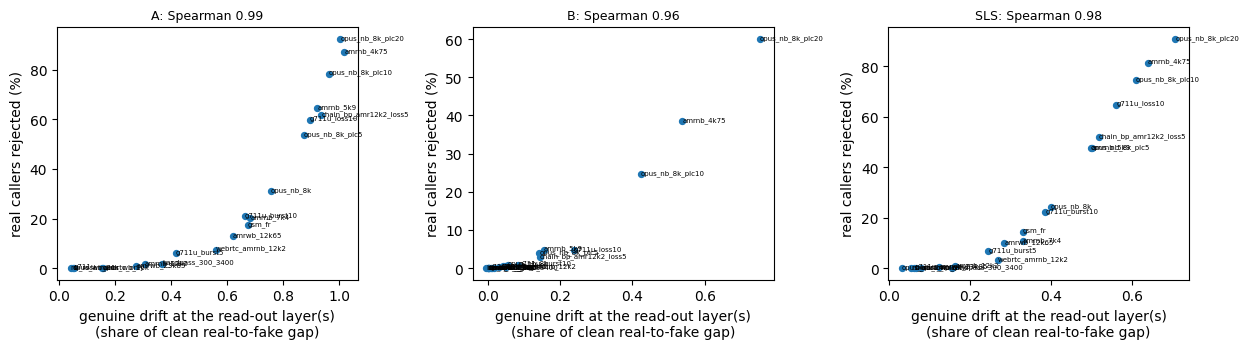

In [12]:
#@title W4-3 · Does the drift at the layers each back end reads predict which stages break it? (seconds)
from scipy.stats import spearmanr
import matplotlib.pyplot as plt
gclean = GATES.groupby('layer').gate_clean.mean().reindex(LAYERS_ALL).values if len(GATES) else None
W_READ = {k: np.eye(24)[23] for k in MODELS if k in ('A', 'B')}       # SSL-AASIST reads the final layer only
if gclean is not None and 'SLS' in MODELS:
    W_READ['SLS'] = gclean / gclean.sum()                              # SLS reads all layers, weighted by its gates
print('XLSR-SLS mean clean gate per layer:', np.round(gclean, 2) if gclean is not None else None)

def feat(k, w, half='test'):
    g = GEO[(GEO.model == k) & (GEO.half == half)]
    piv = lambda cls, col: g[g.cls == cls].pivot(index='stage', columns='layer', values=col)[LAYERS_ALL]
    pg, ps, ng = piv('genuine', 'proj'), piv('spoof', 'proj'), piv('genuine', 'rel_norm')
    return pd.DataFrame({'readout_proj_genuine': pg.values @ w, 'readout_proj_gap': (pg.values - ps.values) @ w,
                         'readout_size_genuine': ng.values @ w,               # control: drift size, ignoring direction
                         'layer23_proj_genuine': pg[23].values, 'layer17_proj_genuine': pg[17].values}, index=pg.index)

PRED = []
TAB = []
for k in MODELS:
    if k not in W_READ:
        continue
    fz = feat(k, W_READ[k])
    bz = BEH[(BEH.model == k) & (BEH.half == 'test')].set_index('stage')
    bz = bz.assign(d_eer=bz.eer - bz.eer_clean).loc[fz.index]
    TAB.append(fz.join(bz[['real_rejected', 'd_eer', 'genuine_shift']]).assign(model=k))
    for target in ('real_rejected', 'd_eer', 'genuine_shift'):
        for pr in fz.columns:
            rho, p = spearmanr(fz[pr], bz[target])
            PRED.append(dict(model=k, predictor=pr, target=target, spearman=rho, p=p, n=len(fz)))
PRED = pd.DataFrame(PRED); TAB = pd.concat(TAB)
PRED.to_csv(f'{W4}/predictor_correlations.csv', index=False); TAB.to_csv(f'{W4}/predictor_table.csv')
print(PRED[PRED.target == 'real_rejected'].pivot(index='predictor', columns='model', values='spearman').round(2))
print(PRED[PRED.target == 'genuine_shift'].pivot(index='predictor', columns='model', values='spearman').round(2))
if 'SLS' in MODELS:
    fz = feat('SLS', np.eye(24)[23]); bz = BEH[(BEH.model == 'SLS') & (BEH.half == 'test')].set_index('stage').loc[fz.index]
    print('SLS check, layer-23 drift instead of its gate-weighted readout: Spearman vs real rejected',
          round(spearmanr(fz.readout_proj_genuine, bz.real_rejected)[0], 2))

fig, axes = plt.subplots(1, len(W_READ), figsize=(4.2 * len(W_READ), 3.6))
for ax, k in zip(np.atleast_1d(axes), W_READ):
    t = TAB[TAB.model == k]
    ax.scatter(t.readout_proj_genuine, 100 * t.real_rejected, s=18)
    for st, r in t.iterrows():
        ax.annotate(st, (r.readout_proj_genuine, 100 * r.real_rejected), fontsize=5)
    rho = PRED[(PRED.model == k) & (PRED.predictor == 'readout_proj_genuine') & (PRED.target == 'real_rejected')].spearman.iloc[0]
    ax.set_title(f'{k}: Spearman {rho:.2f}', fontsize=9); ax.set_xlabel('genuine drift at the read-out layer(s)\n(share of clean real-to-fake gap)')
    ax.set_ylabel('real callers rejected (%)')
fig.tight_layout(); fig.savefig(f"{CFG['OUT']}/figures/week4_predictor.png", dpi=200); plt.show()

In [13]:
#@title W4-4 · Axis split: which part of the drift does the damage? Checkpoint A (about 45-60 min)
_M['m'] = MODELS['A']                       # scores_for() uses this model
Hc_A = INSIDE['A']['clean'][0]
uA = Hc_A[fit & spf].mean(0) - Hc_A[fit & gen].mean(0)
SC_T, rng4 = Sc[test], np.random.default_rng(CFG['SEED'] + 200)
harm = np.load(f'{W4}/drifts/A__g711u.npz')['all_fit'] if os.path.exists(f'{W4}/drifts/A__g711u.npz') else None
SPLIT_ROWS = []
for c in DAMAGING:
    Hx = INSIDE['A'][c][0]; SX_T = INSIDE['A'][c][1][test]
    drop = SC_T[YT == 1].mean() - SX_T[YT == 1].mean()           # genuine-score drop caused by the call, test half
    for L in CFG['SPLIT_LAYERS']:
        v = (Hx - Hc_A)[fit, L].mean(0); uh = uA[L] / np.linalg.norm(uA[L])
        v_par = (v @ uh) * uh; v_perp = v - v_par; nv = np.linalg.norm(v)
        V_ADD = {'drift v': v, 'axis part only': v_par, 'orthogonal part only': v_perp,
                 'axis direction, scaled to |v|': uh * nv * np.sign(v @ uh)}
        if harm is not None:
            V_ADD['harmless-stage drift (G.711), scaled to |v|'] = harm[L] / np.linalg.norm(harm[L]) * nv
        for j in range(CFG['N_RAND']):
            r = rng4.standard_normal(1024).astype(np.float32); V_ADD[f'random {j}'] = r / np.linalg.norm(r) * nv
        for name, vec in V_ADD.items():
            s = scores_for(f'w4_{c}__add_{name.split(",")[0].replace(" ", "_").replace("|", "")}__L{L}', 'clean', 'test',
                           lambda m, vec=vec: P.LayerShift(m, L, vec))
            SPLIT_ROWS.append(dict(stage=c, layer=L, test='add to clean', variant=name, share_of_call_drop=(SC_T[YT == 1].mean() - s[YT == 1].mean()) / drop,
                                   **ci_eer(s), **op(s), norm_rel_v=np.linalg.norm(vec) / nv, cos_axis=float(vec @ uh / (np.linalg.norm(vec) + 1e-12))))
        for name, vec in {'drift v': v, 'axis part only': v_par, 'orthogonal part only': v_perp}.items():
            s = scores_for(f'w4_{c}__remove_{name.split(" ")[0]}__L{L}', c, 'test', lambda m, vec=vec: P.LayerShift(m, L, -vec))
            SPLIT_ROWS.append(dict(stage=c, layer=L, test='remove from call', variant=name,
                                   share_of_call_drop=(s[YT == 1].mean() - SX_T[YT == 1].mean()) / drop,
                                   **ci_eer(s, SX_T), **op(s), norm_rel_v=np.linalg.norm(vec) / nv, cos_axis=float(vec @ uh / (np.linalg.norm(vec) + 1e-12))))
        print(f'{c} L{L}: |v_par|/|v| = {np.linalg.norm(v_par) / nv:.2f}')
    WAV.pop((c, 'test'), None)
SPLIT_DF = pd.DataFrame(SPLIT_ROWS); SPLIT_DF.to_csv(f'{W4}/axis_split.csv', index=False)
show = SPLIT_DF.assign(variant=SPLIT_DF.variant.str.replace(r'random \d+', 'random (mean)', regex=True))
show = show.groupby(['stage', 'layer', 'test', 'variant'], sort=False)[['share_of_call_drop', 'eer', 'real_rejected', 'fakes_accepted', 'genuine_mean', 'cos_axis', 'norm_rel_v']].mean()
display(show.round(3))

g711u_loss10 L11: |v_par|/|v| = 0.86
g711u_loss10 L17: |v_par|/|v| = 0.91
amrnb_4k75 L11: |v_par|/|v| = 0.82
amrnb_4k75 L17: |v_par|/|v| = 0.91
opus_nb_8k L11: |v_par|/|v| = 0.81
opus_nb_8k L17: |v_par|/|v| = 0.89


share_of_call_drop  \
stage        layer test             variant                                                           
g711u_loss10 11    add to clean     drift v                                                   0.124   
                                    axis part only                                            0.114   
                                    orthogonal part only                                      0.002   
                                    axis direction, scaled to |v|                             0.172   
                                    harmless-stage drift (G.711), scaled to |v|               0.008   
                                    random (mean)                                             0.001   
                   remove from call drift v                                                   0.355   
                                    axis part only                                            0.383   
                                    orthogonal part only                                     -0.009   
             17    add to clean     drift v                                                   0.291   
                                    axis part only                                            0.272   
                                    orthogonal part only                                      0.005   
                                    axis direction, scaled to |v|                             0.355   
                                    harmless-stage drift (G.711), scaled to |v|               0.011   
                                    random (mean)                                            -0.003   
                   remove from call drift v                                                   0.457   
                                    axis part only                                            0.501   
                                    orthogonal part only                                     -0.009   
amrnb_4k75   11    add to clean     drift v                                                   0.221   
                                    axis part only                                            0.136   
                                    orthogonal part only                                      0.001   
                                    axis direction, scaled to |v|                             0.237   
                                    harmless-stage drift (G.711), scaled to |v|               0.008   
                                    random (mean)                                            -0.003   
                   remove from call drift v                                                   0.170   
                                    axis part only                                            0.133   
                                    orthogonal part only                                      0.001   
             17    add to clean     drift v                                                   0.521   
                                    axis part only                                            0.522   
                                    orthogonal part only                                      0.003   
                                    axis direction, scaled to |v|                             0.618   
                                    harmless-stage drift (G.711), scaled to |v|               0.015   
                                    random (mean)                                             0.004   
                   remove from call drift v                                                   0.333   
                                    axis part only                                            0.399   
                                    orthogonal part only                                     -0.004   
opus_nb_8k   11    add to clean     drift v                                                   0.063   
                                    axis part only              

In [14]:
#@title W4-5 · Summary for Claude, and the zip for GitHub (1 min)
import io, zipfile, contextlib
buf = io.StringIO()
with contextlib.redirect_stdout(buf):
    pd.set_option('display.width', 250); pd.set_option('display.max_rows', 500); pd.set_option('display.max_columns', 30)
    print('WEEK 4 SUMMARY'); print('models:', list(MODELS), '| thresholds:', {k: round(float(TH[k]['dev_EER']), 3) for k in MODELS})
    print('XLSR-SLS clean dev EER (%):', round(100 * P.eer(b_, f_)[0], 2))
    print('\nBEHAVIOUR, test half (%):')
    bt = BEH[BEH.half == 'test'].copy()
    for col in ('eer', 'eer_clean', 'real_rejected', 'fakes_accepted'):
        bt[col] = (100 * bt[col]).round(1)
    print(bt.drop(columns='half').round(3).to_string(index=False))
    print('\nGEOMETRY, test half, genuine/spoof projection at layers 3,5,7,11,17,21,23:')
    gt = GEO[(GEO.half == 'test') & GEO.cls.isin(['genuine', 'spoof']) & GEO.layer.isin([3, 5, 7, 11, 17, 21, 23])]
    print(gt.pivot_table(index=['model', 'stage', 'cls'], columns='layer', values='proj').round(2).to_string())
    print('\nCOSINE of genuine drift with the axis, test half:')
    print(GEO[(GEO.half == 'test') & (GEO.cls == 'genuine') & GEO.layer.isin([3, 7, 11, 17, 21, 23])]
          .pivot_table(index=['model', 'stage'], columns='layer', values='cos').round(2).to_string())
    print('\nXLSR-SLS GATES (mean over utterances):'); print(GATES.groupby('layer')[['gate_clean', 'gate_stage']].mean().round(3).T.to_string())
    print('\nPREDICTOR (Spearman across stages, test half):'); print(PRED.round(3).to_string(index=False))
    print('\nPREDICTOR TABLE:'); print(TAB.round(3).to_string())
    print('\nAXIS SPLIT (checkpoint A, test half):'); print(SPLIT_DF.drop(columns=[c for c in SPLIT_DF.columns if c.startswith('d_')]).round(3).to_string(index=False))
open(f'{W4}/week4_summary.txt', 'w').write(buf.getvalue()); print(buf.getvalue())

zp = '/kaggle/working/week4_for_github.zip'
with zipfile.ZipFile(zp, 'w', zipfile.ZIP_DEFLATED) as z:
    for f in glob.glob(f'{W4}/*.csv') + glob.glob(f'{W4}/*.txt') + glob.glob(f'{W4}/scores/*.csv') + glob.glob(f'{W4}/drifts/*.npz'):
        z.write(f, os.path.relpath(f, CFG['OUT']))
    for f in glob.glob(f"{CFG['OUT']}/figures/week4_*.png"):
        z.write(f, os.path.relpath(f, CFG['OUT']))
print(zp, os.path.getsize(zp) // 1024, 'KB')

WEEK 4 SUMMARY
models: ['A', 'B', 'SLS'] | thresholds: {'A': -3.437, 'B': -2.762, 'SLS': -9.364}
XLSR-SLS clean dev EER (%): 0.0

BEHAVIOUR, test half (%):
model                  stage  eer  eer_clean  real_rejected  fakes_accepted  genuine_shift  spoof_shift
    A      bandpass_300_3400  3.0        0.0            1.8             3.6         -2.006        0.036
    B      bandpass_300_3400  0.0        0.0            0.0             1.7         -0.093       -0.235
  SLS      bandpass_300_3400  1.7        0.0            0.0             4.1         -0.441        0.656
    A            nb_resample  0.0        0.0            0.0             2.6         -0.070        0.003
    B            nb_resample  0.0        0.0            0.0             1.1         -0.065       -0.326
  SLS            nb_resample  0.0        0.0            0.0             2.3         -0.023       -0.114
    A                  g711u  0.2        0.0            0.0             2.6         -0.096       -0.002
    B       